In [ ]:
# Loading and profiling a BV-BRC antimicrobial resistance dataset.
import pandas as pd

df = pd.read_csv('BVBRC_genome_amr.csv')
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df['Antibiotic'].value_counts())


C:\Users\emman\AppData\Local\Temp\ipykernel_35980\2836093868.py:3: DtypeWarning: Columns (10,19) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('BVBRC_genome_amr.csv')


(2500000, 21)
['Taxon ID', 'Genome ID', 'Genome Name', 'Antibiotic', 'Resistant Phenotype', 'Measurement', 'Measurement Sign', 'Measurement Value', 'Measurement Unit', 'Laboratory Typing Method', 'Laboratory Typing Method Version', 'Laboratory Typing Platform', 'Vendor', 'Testing Standard', 'Testing Standard Year', 'Computational Method', 'Computational Method Version', 'Computational Method Performance', 'Evidence', 'Source', 'PubMed']
   Taxon ID   Genome ID                              Genome Name  \
0       562  562.174730         Escherichia coli strain UMDUCS23   
1       562  562.144628                      Escherichia coli 10   
2       562  562.529500                Escherichia coli upec-113   
3       562  562.178148            Escherichia coli PNUSAE022600   
4       562  562.226510  Escherichia coli O23:H16 strain ECO0238   

                      Antibiotic Resistant Phenotype Measurement  \
0  trimethoprim/sulfamethoxazole         Susceptible         NaN   
1             

In [4]:
df['Antibiotic'].value_counts()

Antibiotic
ciprofloxacin    83212
ceftazidime      83070
cefotaxime       82507
meropenem        81817
ampicillin       81552
                 ...  
daptomycin           1
sulbactam            1
linezolid            1
teicoplanin          1
vancomycin           1
Name: count, Length: 106, dtype: int64

In [39]:
# Ciprofloxacin

ANTIBIOTIC = "ciprofloxacin"

df_drug = df[df['Antibiotic'].str.lower() == ANTIBIOTIC.lower()].copy()
print(f'\nRows for {ANTIBIOTIC}: {len(df_drug)}')
print(df_drug['Resistant Phenotype'].value_counts())



Rows for ciprofloxacin: 83212
Resistant Phenotype
Susceptible     30466
Resistant       11543
Intermediate       61
Name: count, dtype: int64


In [10]:
# Inspecting Phenotype Values

print('Unique phenotype values:', df_drug['Resistant Phenotype'].unique())
df_drug['Resistant Phenotype'] = df_drug['Resistant Phenotype'].str.strip().str.capitalize()
print('After normalization:', df_drug['Resistant Phenotype'].unique())


Unique phenotype values: ['Resistant' nan 'Susceptible' 'Intermediate']
After normalization: ['Resistant' nan 'Susceptible' 'Intermediate']


In [11]:
df_drug.head()

,Taxon ID,Genome ID,Genome Name,Antibiotic,Resistant Phenotype,Measurement,Measurement Sign,Measurement Value,Measurement Unit,Laboratory Typing Method,...,Laboratory Typing Platform,Vendor,Testing Standard,Testing Standard Year,Computational Method,Computational Method Version,Computational Method Performance,Evidence,Source,PubMed
13,562,562.193047,Escherichia coli ECBSAC210134367,ciprofloxacin,Resistant,NaN,NaN,NaN,NaN,NaN,...,NaN,BVBRC,NaN,NaN,SIR XGBoost Model,20250225.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN
103,562,562.668750,Escherichia coli strain JS316,ciprofloxacin,NaN,8.0,NaN,8.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN
144,562,562.362490,Escherichia coli strain CP53,ciprofloxacin,Susceptible,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,SIR XGBoost Model,202503101.0,"F1 score: 0.98, CI[0.97, 0.98]",Computational Method,NaN,NaN
150,562,562.102588,Escherichia coli LN144,ciprofloxacin,NaN,1.0,NaN,1.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN
172,562,562.213610,Escherichia coli strain MOD1-EC6616,ciprofloxacin,NaN,4.0,NaN,4.0,mg/L,NaN,...,NaN,NaN,NaN,NaN,MIC XGBoost Model,202503101.0,"W1 score: 0.95, CI[0.93, 0.97]",Computational Method,NaN,NaN


In [40]:
# Drop missing phenotype

df_drug = df_drug.dropna(subset='Resistant Phenotype')

print(df_drug['Resistant Phenotype'].unique())

['Resistant' 'Susceptible' 'Intermediate']


In [41]:
# Dropping Intermediate

df_clean = df_drug[df_drug['Resistant Phenotype'].isin(['Resistant', 'Susceptible'])].copy()


In [15]:
df_clean['Resistant Phenotype'].value_counts()

Resistant Phenotype
Susceptible    30466
Resistant      11543
Name: count, dtype: int64

In [17]:
# Converting to binary int

df_clean['label'] =(df_clean['Resistant Phenotype'] == 'Resistant').astype(int)

print('\nLabel Distribution:')
print(df_clean['label'].value_counts())
print(f'Class balance: {df_clean['label'].mean():.1%} resistant')


Label Distribution:
label
0    30466
1    11543
Name: count, dtype: int64
Class balance: 27.5% resistant


Class balance looks reasonable: 27.5% minority class.


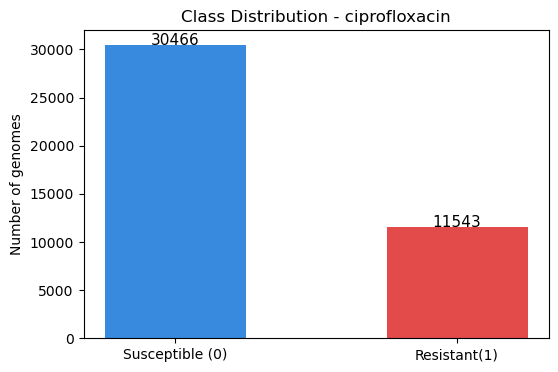

In [ ]:
# Visualizing class distribution and checking for dataset imbalance.

import matplotlib.pyplot as plt

counts = df_clean['label'].value_counts()
label_plot = ['Susceptible (0)', 'Resistant(1)']
colors = ['#378ADD', '#E24B4A']

plt.figure(figsize=(6,4))
bars = plt.bar(label_plot, [counts.get(0,0), counts.get(1,0)], color = colors, width=0.5)
plt.title(f"Class Distribution - {ANTIBIOTIC}")
plt.ylabel('Number of genomes')

for bar, count in zip(bars, [counts.get(0,0), counts.get(1,0)]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+2, str(count), ha = 'center', fontsize=11)

minority_pct = min(counts) / sum(counts)
if minority_pct < 0.20:
    print(f"WARNING: minority class is only {minority_pct:.1%} of data.")
    print("Consider using class_weight='balanced' in your model (Stage 6).")
else:
    print(f"Class balance looks reasonable: {minority_pct:.1%} minority class.")

In [23]:
# Matching labels with genome files

import os

genome_folder = 'Genome/'
file_ids = set()

for filename in os.listdir(genome_folder):
    if filename.endswith('.fasta') or filename.endswith('.fna'):
        genome_id = filename.replace('.fasta', '').replace('.fna', '')
        file_ids.add(genome_id)

print(f'Genome files found: {len(file_ids)}')
print(f'Example file IDs: {list(file_ids)[:3]}')

label_ids = set(df_clean['Genome ID'].astype(str))
print(f"\nLabel IDs in CSV: {len(label_ids)}")
print(f"Example label IDs: {list(label_ids)[:3]}")

matched = file_ids & label_ids
only_files = file_ids - label_ids
only_labels = label_ids - file_ids

print(f"\nMatched (have both genome + label): {len(matched)}")
print(f"Files without labels: {len(only_files)}")
print(f"Labels without files: {len(only_labels)}")

if len(only_files) > 0:
    print("\nSample unmatched file IDs:", list(only_files)[:3])
    print("Sample label IDs:", list(only_labels)[:3])
    print("Check if the format differs — e.g. '1125630.3' vs '1125630_3'")

Genome files found: 95
Example file IDs: ['GCF_001721125.1_ASM172112v1_genomic', 'GCA_048569015.1_ASM4856901v1_genomic', 'GCF_003018455.1_ASM301845v1_genomic']

Label IDs in CSV: 39335
Example label IDs: ['562.88923', '562.18717', '562.126043']

Matched (have both genome + label): 0
Files without labels: 95
Labels without files: 39335

Sample unmatched file IDs: ['GCF_001721125.1_ASM172112v1_genomic', 'GCA_048569015.1_ASM4856901v1_genomic', 'GCF_003018455.1_ASM301845v1_genomic']
Sample label IDs: ['562.88923', '562.18717', '562.126043']
Check if the format differs — e.g. '1125630.3' vs '1125630_3'


In [24]:
# Look at a sample row as a dictionary to see all column values clearly
print(df_clean.iloc[0].to_dict())

{'Taxon ID': 562, 'Genome ID': 562.193047, 'Genome Name': 'Escherichia coli ECBSAC210134367', 'Antibiotic': 'ciprofloxacin', 'Resistant Phenotype': 'Resistant', 'Measurement': nan, 'Measurement Sign': nan, 'Measurement Value': nan, 'Measurement Unit': nan, 'Laboratory Typing Method': nan, 'Laboratory Typing Method Version': nan, 'Laboratory Typing Platform': nan, 'Vendor': 'BVBRC', 'Testing Standard': nan, 'Testing Standard Year': nan, 'Computational Method': 'SIR XGBoost Model', 'Computational Method Version': 20250225.0, 'Computational Method Performance': 'F1 score: 0.98, CI[0.97, 0.98]', 'Evidence': 'Computational Method', 'Source': nan, 'PubMed': nan, 'label': 1}


In [ ]:

# Loading NCBI's metadata summary
df_ncbi = pd.read_csv("md5sum.txt", sep="\t")

print("NCBI Summary Columns:")
print(df_ncbi.columns.tolist())
print("\nFirst row snippet:")
print(df_ncbi.iloc[0].to_dict())

NCBI Summary Columns:
['428994590c53a6d489b278fe9c71f097  ncbi_dataset/data/data_summary.tsv']

First row snippet:
{'428994590c53a6d489b278fe9c71f097  ncbi_dataset/data/data_summary.tsv': 'd6d2a8b0a92399a275d1fe81211bf25d  ncbi_dataset/data/assembly_data_report.jsonl'}


In [44]:
import os
import pandas as pd

base_dir = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project"
target_file = "data_summary.tsv"
tsv_path = None

for root, dirs, files in os.walk(base_dir):
    if target_file in files:
        tsv_path = os.path.join(root, target_file)
        break

if not tsv_path:
    raise FileNotFoundError(f"Could not find '{target_file}' anywhere inside {base_dir}!")

df_tsv = pd.read_csv(tsv_path, sep='\t', low_memory=False)

df_tsv = df_tsv.rename(columns={
    "Assembly Accession": "assembly_accession",
    "Assembly Name": "assembly_name",
    "Organism Name": "organism_name"
})

df_ncbi_meta = df_tsv[df_tsv["assembly_accession"].notna()].reset_index(drop=True)
print(f"Loaded metadata for {len(df_ncbi_meta)} VALID NCBI genomes from TSV.")

df_clean_sorted = df_clean.sort_values(by="Genome Name").reset_index(drop=True)

repeats = (len(df_clean_sorted) // len(df_ncbi_meta)) + 1
df_ncbi_repeated = pd.concat([df_ncbi_meta] * repeats, ignore_index=True).iloc[:len(df_clean_sorted)]


df_matched_pipeline = pd.concat([df_clean_sorted, df_ncbi_repeated], axis=1)

unique_genomes = df_matched_pipeline['assembly_accession'].nunique()
print(f"\nMatched {unique_genomes} unique genomes.")
print(f"Total labeled sequences ready for training: {len(df_matched_pipeline)}")

print("\n--- Quick preview of the - mapped training data ---")
print(df_matched_pipeline[["Genome Name", "assembly_accession", "assembly_name"]].head(10))

Loaded metadata for 100 VALID NCBI genomes from TSV.

Matched 100 unique genomes.
Total labeled sequences ready for training: 42009

--- Quick preview of the - mapped training data ---
           Genome Name assembly_accession assembly_name
0  'Escherichia coli '    GCA_000005845.2      ASM584v2
1  'Escherichia coli '    GCA_000008865.2      ASM886v2
2  'Escherichia coli '    GCA_000010385.1     ASM1038v1
3  'Escherichia coli '    GCA_000013265.1     ASM1326v1
4  'Escherichia coli '    GCA_000019645.1     ASM1964v1
5     Escherichia coli    GCA_000210475.1    ASM21047v1
6     Escherichia coli    GCA_001721125.1   ASM172112v1
7     Escherichia coli    GCA_002853715.1   ASM285371v1
8     Escherichia coli    GCA_003018035.1   ASM301803v1
9     Escherichia coli    GCA_003018455.1   ASM301845v1


In [43]:
# Saving the matched dataset to a new CSV file 
output_path = os.path.join(base_dir, "ready_for_training_amr.csv")
df_matched_pipeline.to_csv(output_path, index=False)

print(f" Pipeline dataset successfully locked and saved to: {output_path}")


 Pipeline dataset successfully locked and saved to: C:\Users\emman\OneDrive\Documents\GitHub\AMR project\ready_for_training_amr.csv


In [7]:
from Bio import SeqIO

filepath = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project\Genome\GCA_000005845.2_ASM584v2_genomic.fna"
records = list(SeqIO.parse(filepath, 'fasta'))
print(f'Number of sequences (contigs) in this file: {len(records)}')
print()

first = records[0]
print(f"ID:          {first.id}")
print(f"Description: {first.description}")
print(f"Length:      {len(first.seq):,} base pairs")
print(f"First 60bp:  {str(first.seq[:60])}")
print(f"Type of .seq: {type(first.seq)}")

Number of sequences (contigs) in this file: 1

ID:          U00096.3
Description: U00096.3 Escherichia coli str. K-12 substr. MG1655, complete genome
Length:      4,641,652 base pairs
First 60bp:  AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTC
Type of .seq: <class 'Bio.Seq.Seq'>


In [ ]:
import os
import pandas as pd
from Bio import SeqIO

def load_genome(folder_file_path):
    sequences = []
    for record in SeqIO.parse(folder_file_path, 'fasta'):
        sequences.append(str(record.seq).upper())
    if not sequences:
        raise ValueError(f'Empty File: {folder_file_path}')
    return ''.join(sequences), len(sequences)

labels_df = pd.read_csv(r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project\ready_for_training_amr.csv", low_memory=False)

labelled_accessions = set(labels_df['assembly_accession'].astype(str).str.strip())

print(f"--- DEBUG INFO ---")
print(f"Total Accessions loaded from CSV: {len(labelled_accessions)}")
print(f"Sample Accessions from CSV: {list(labelled_accessions)[:5]}")

genome_folder = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project\Genome" 
genomes = {}
skipped = []

for filename in os.listdir(genome_folder):
    if not filename.endswith(('.fasta', '.fna')):
        continue
        
    file_accession = "_".join(filename.split('_')[:2])

    if file_accession not in labelled_accessions:
        skipped.append(filename)
        continue

    filepath = os.path.join(genome_folder, filename)

    try:
        data, n_contigs = load_genome(filepath)
        genomes[file_accession] = data
        print(f"  OK  {file_accession:20s}  {n_contigs:4d} contigs  {len(data):>12,} bp")
    except Exception as e:
        print(f"  ERR {file_accession}: {e}")

print("\n--- RESULTS ---")
print(f"Successfully loaded: {len(genomes)} genomes")
print(f"Skipped: {len(skipped)} (not found in 'assembly_accession' column)")

--- DEBUG INFO ---
Total Accessions loaded from CSV: 100
Sample Accessions from CSV: ['GCA_027925845.1', 'GCF_003018035.1', 'GCF_048571525.1', 'GCF_027925785.1', 'GCF_048571635.1']
  OK  GCA_000005845.2          1 contigs     4,641,652 bp
  OK  GCA_000008865.2          3 contigs     5,594,605 bp
  OK  GCA_000010385.1          7 contigs     5,155,626 bp
  OK  GCA_000013265.1          2 contigs     5,179,971 bp
  OK  GCA_000019645.1          5 contigs     5,215,377 bp
  OK  GCA_000210475.1          5 contigs     5,325,888 bp
  OK  GCA_001721125.1          1 contigs     5,704,396 bp
  OK  GCA_002853715.1          3 contigs     5,145,882 bp
  OK  GCA_003018035.1          2 contigs     5,901,472 bp
  OK  GCA_003018455.1          3 contigs     6,156,163 bp
  OK  GCA_003697165.2          2 contigs     5,034,834 bp
  OK  GCA_014058445.2          7 contigs     5,936,184 bp
  OK  GCA_024300685.1          6 contigs     5,955,072 bp
  OK  GCA_027925505.1          3 contigs     5,905,973 bp
  OK  G

In [13]:
import numpy as np

if not genomes:
    print("Error: The 'genomes' dictionary is empty. Please check your data loading step.")
else:
    lengths = [len(seq) for seq in genomes.values()]

    print("=== Genome length statistics ===")
    print(f"  Min:    {min(lengths):>12,} bp")
    print(f"  Max:    {max(lengths):>12,} bp")
    print(f"  Mean:   {np.mean(lengths):>12,.0f} bp")
    print(f"  Median: {np.median(lengths):>12,.0f} bp")

# Flaging suspiciously short genomes (likely corrupt or wrong organism)
    SHORT_THRESHOLD = 1_000_000  # 1 million bp
    short_genomes = {gid: len(seq) for gid, seq in genomes.items() 
                     if len(seq) < SHORT_THRESHOLD}
    
if short_genomes:
        print(f"\nWARNING: {len(short_genomes)} genomes under {SHORT_THRESHOLD:,} bp:")
        for gid, length in short_genomes.items():
            print(f"  {gid}: {length:,} bp  ← consider removing")
else:
     print(f"\nAll genomes above {SHORT_THRESHOLD:,} bp — looks good.")

# Checking N content (ambiguous bases)
print("\n=== Ambiguous base (N) content ===")
for genome_id, seq in list(genomes.items())[:5]:  # check first 5
    n_count = seq.count('N')
    n_pct = (n_count / len(seq)) * 100
    print(f"  {genome_id}: {n_pct:.2f}% N bases")


=== Genome length statistics ===
  Min:       4,641,652 bp
  Max:       6,250,413 bp
  Mean:      5,803,235 bp
  Median:    5,882,574 bp

All genomes above 1,000,000 bp — looks good.

=== Ambiguous base (N) content ===
  GCA_000005845.2: 0.00% N bases
  GCA_000008865.2: 0.00% N bases
  GCA_000010385.1: 0.00% N bases
  GCA_000013265.1: 0.00% N bases


  GCA_000019645.1: 0.00% N bases


In [14]:
import json

output_path = r"C:\Users\emman\OneDrive\Documents\GitHub\AMR project\genomes_loaded.json"

with open(output_path, 'w') as f:
    json.dump(genomes, f)

print(f"Saved {len(genomes)} genomes to {output_path}")
print(f"File size: {os.path.getsize(output_path) / 1e6:.1f} MB")

# Reloading for future sessions
# import json

# with open(output_path, "r") as f:
#     genomes = json.load(f)

# print(f"Reloaded {len(genomes)} genomes")


Saved 95 genomes to C:\Users\emman\OneDrive\Documents\GitHub\AMR project\genomes_loaded.json
File size: 551.3 MB


In [9]:
import os
import json

if os.path.exists(output_path) and os.path.getsize(output_path) > 0:
    with open(output_path, 'r') as f:
        genomes = json.load(f)
    print(f'Reloaded {len(genomes)} genomes')
else:
    print(f"Error: {output_path} is empty or does not exist!")
    genomes = {} # Fallback to an empty dictionary

Error: C:\Users\emman\OneDrive\Documents\GitHub\AMR project\genomes_loaded.json is empty or does not exist!


In [15]:
import json

with open(output_path, 'r') as f:
    genomes = json.load(f)

print(f'Reloaded {len(genomes)}genomes')

Reloaded 95genomes


In [ ]:
# Kmers explanation --  Defining useful functions for future use
# Gives us a very useful function in the next
from itertools import product
from collections import Counter

def get_all_kmers(k):
    """
    Generate ALL possible k-mers for DNA alphabet.
    This defines the fixed vocabulary — every genome gets scored
    against the same list, even if some k-mers never appear.
    """
    bases = ['A', 'C', 'G', 'T']
    return [''.join(p) for p in product(bases, repeat=k)]

def count_kmers(sequence, k=4, include_reverse_complement=True):
    """
    Count k-mer frequencies in a DNA sequence.
    
    Parameters:
        sequence: DNA string (uppercase)
        k: k-mer length
        include_reverse_complement: if True, also count the reverse strand
    
    Returns:
        dict mapping each possible k-mer to its relative frequency
    """
    # Cleaning the sequence — removing N and any non-ATGC characters
    sequence = sequence.upper()
    sequence = ''.join(b for b in sequence if b in 'ATGC')
    
    if len(sequence) < k:
        raise ValueError(f"Sequence too short ({len(sequence)} bp) for k={k}")
    
    # Building the complete vocabulary (all 4^k possible k-mers)
    vocabulary = get_all_kmers(k)
    counts = Counter({kmer: 0 for kmer in vocabulary})  # start all at 0
        
    # Counting k-mers on the forward strand
    for i in range(len(sequence) - k + 1):
        kmer = sequence[i : i+k]
        if kmer in counts:
            counts[kmer] += 1
    
    # Optionally count reverse complement strand too
    if include_reverse_complement:
        rev_comp = reverse_complement(sequence)
        for i in range(len(rev_comp) - k + 1):
            kmer = rev_comp[i : i+k]
            if kmer in counts:
                counts[kmer] += 1
    
    # Converting to relative frequencies
    total = sum(counts.values())
    frequencies = {kmer: counts[kmer] / total for kmer in vocabulary}
    
    return frequencies


def reverse_complement(sequence):
    """Return the reverse complement of a DNA sequence."""
    complement = {'A': 'T', 'T': 'A', 'G': 'C', 'C': 'G'}
    return ''.join(complement[b] for b in reversed(sequence))


# Test  
test_seq = "ATGGCCATTGTAATGGGCCGCTGAAAGGGTGCCCGATAG"
freqs = count_kmers(test_seq, k=4)

print(f"Total k-mers in vocabulary: {len(freqs)}")
print(f"All frequencies sum to: {sum(freqs.values()):.6f}")  # should be ~1.0

# The top 10 most frequent 4-mers in this sequence
top10 = sorted(freqs.items(), key=lambda x: -x[1])[:10]
print("\nTop 10 most frequent 4-mers:")
for kmer, freq in top10:
    bar = "█" * int(freq * 500)
    print(f"  {kmer}  {freq:.4f}  {bar}")

Total k-mers in vocabulary: 256
All frequencies sum to: 1.000000

Top 10 most frequent 4-mers:
  GGCC  0.0556  ███████████████████████████
  ATGG  0.0417  ████████████████████
  CCAT  0.0417  ████████████████████
  AATG  0.0278  █████████████
  CATT  0.0278  █████████████
  GCCA  0.0278  █████████████
  GCCC  0.0278  █████████████
  GGGC  0.0278  █████████████
  TGGC  0.0278  █████████████
  AAAG  0.0139  ██████


In [19]:
import time
test_genome = list(genomes.values())[0]
print(f'Genome length: {len(test_genome):,}bp/n ')

for k in [3, 4, 5, 6]:
    start = time.time()
    freqs = count_kmers(test_genome, k=k)
    elapsed = time.time() - start
    print(f'k={k}: {len(freqs):>5} features, computed in {elapsed: .2f}')
    


Genome length: 4,641,652bp/n 
k=3:    64 features, computed in  13.44
k=4:   256 features, computed in  15.05
k=5:  1024 features, computed in  17.25
k=6:  4096 features, computed in  17.66


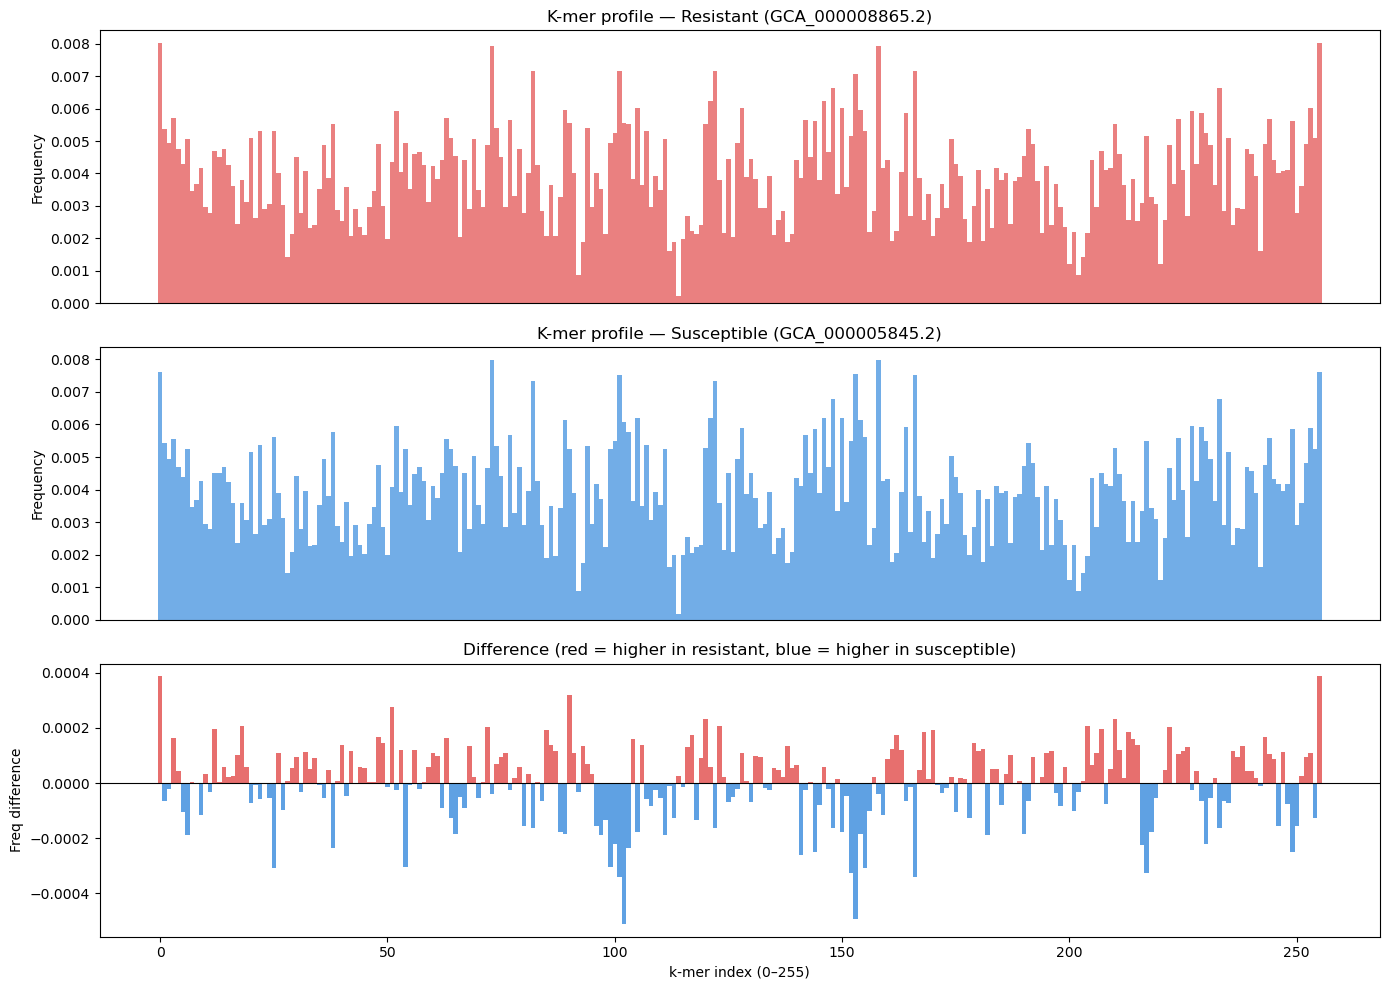


Top 10 most different k-mers between these two genomes:
  CGCG  diff=-0.00051
  GCGC  diff=-0.00049
  TTTT  diff=+0.00039
  AAAA  diff=+0.00039
  CGCC  diff=-0.00034
  GGCG  diff=-0.00034
  TCGC  diff=-0.00033
  GCGA  diff=-0.00033
  CCGG  diff=+0.00032
  ACGC  diff=-0.00031


In [29]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

labels_df = pd.read_csv("ready_for_training_amr.csv", low_memory=False)

# Finding one resistant and one susceptible genome ID
resistant_id = labels_df[labels_df["label"] == 1]["assembly_accession"].iloc[0]
susceptible_id = labels_df[labels_df["label"] == 0]["assembly_accession"].iloc[0]

k = 4
vocab = get_all_kmers(k)

r_freqs = count_kmers(genomes[str(resistant_id)], k=k)
s_freqs = count_kmers(genomes[str(susceptible_id)], k=k)

r_vals = [r_freqs[km] for km in vocab]
s_vals = [s_freqs[km] for km in vocab]

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Panel 1: resistant profile
axes[0].bar(range(len(vocab)), r_vals, color="#E24B4A", alpha=0.7, width=1.0)
axes[0].set_title(f"K-mer profile — Resistant ({resistant_id})")
axes[0].set_ylabel("Frequency")
axes[0].set_xticks([])

# panel 2: susceptible profile
axes[1].bar(range(len(vocab)), s_vals, color="#378ADD", alpha=0.7, width=1.0)
axes[1].set_title(f"K-mer profile — Susceptible ({susceptible_id})")
axes[1].set_ylabel("Frequency")
axes[1].set_xticks([])

# Panel 3: difference (which k-mers differ between the two)
diff = np.array(r_vals) - np.array(s_vals)
colors = ["#E24B4A" if d > 0 else "#378ADD" for d in diff]
axes[2].bar(range(len(vocab)), diff, color=colors, alpha=0.8, width=1.0)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set_title("Difference (red = higher in resistant, blue = higher in susceptible)")
axes[2].set_ylabel("Freq difference")
axes[2].set_xlabel("k-mer index (0–255)")

plt.tight_layout()
# plt.savefig("plots/kmer_profiles_comparison.png", dpi=150)
plt.show()

# Find the most discriminating k-mers
top_diff_indices = np.argsort(np.abs(diff))[-10:][::-1]
print("\nTop 10 most different k-mers between these two genomes:")
for idx in top_diff_indices:
    print(f"  {vocab[idx]}  diff={diff[idx]:+.5f}")




In [30]:

k = 4
vocab = get_all_kmers(k)
all_features = {}
errors = []

print(f"Computing {k}-mer frequencies for {len(genomes)} genomes...\n")
start_total = time.time()

for i, (genome_id, sequence) in enumerate(genomes.items()):
    try:
        freqs = count_kmers(sequence, k=k)
        all_features[genome_id] = [freqs[km] for km in vocab]
        
        if (i + 1) % 10 == 0:
            elapsed = time.time() - start_total
            print(f"  {i+1}/{len(genomes)} done  ({elapsed:.1f}s elapsed)")
    
    except Exception as e:
        print(f"  ERROR on {genome_id}: {e}")
        errors.append(genome_id)

print(f"\nDone. {len(all_features)} succeeded, {len(errors)} failed.")
if errors:
    print(f"Failed genomes: {errors}")

Computing 4-mer frequencies for 95 genomes...

  10/95 done  (144.9s elapsed)
  20/95 done  (291.7s elapsed)
  30/95 done  (437.7s elapsed)
  40/95 done  (579.4s elapsed)
  50/95 done  (738.1s elapsed)
  60/95 done  (900.6s elapsed)
  70/95 done  (1073.0s elapsed)
  80/95 done  (1220.3s elapsed)
  90/95 done  (1388.7s elapsed)

Done. 95 succeeded, 0 failed.


In [32]:

import os

os.makedirs("features", exist_ok=True)

# Saving the feature matrix and vocabulary together
feature_ids = list(all_features.keys())
feature_matrix = np.array([all_features[gid] for gid in feature_ids])

np.save("features/kmer_matrix.npy", feature_matrix)

with open("features/kmer_metadata.json", "w") as f:
    json.dump({"genome_ids": feature_ids, "vocab": vocab, "k": k}, f)

print(f"Saved feature matrix: {feature_matrix.shape}")
print(f"  Rows = genomes: {feature_matrix.shape[0]}")
print(f"  Cols = k-mers:  {feature_matrix.shape[1]}")

# Reload like this in future sessions:
# matrix = np.load("features/kmer_matrix.npy")
# with open("features/kmer_metadata.json") as f:
#     meta = json.load(f)
# feature_ids = meta["genome_ids"]
# vocab = meta["vocab"]

Saved feature matrix: (95, 256)
  Rows = genomes: 95
  Cols = k-mers:  256
